# TP3 · Paso 2 — Model-centered: baseline, validación cruzada y métricas

Enfoque **centrado en el modelo**: con los datos fijos (las 28 variables originales limpias del paso 1) buscamos un clasificador y unos hiperparámetros razonables que sirvan de **baseline**.

- 2.1 Clasificadores vistos en clase + breve calibración de hiperparámetros.
- 2.2 k-fold cross-validation **sólo sobre train**.
- 2.3 Dos métricas y su justificación.

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

import tp3_comun as C

X_train, y_train = C.cargar_split("train")
grupos = C.firma_duplicados(X_train)
C.RESULTADOS.mkdir(exist_ok=True)
print(X_train.shape, f"tasa cancel = {y_train.mean():.3f}")

(38268, 28) tasa cancel = 0.417


## 2.3 Métricas elegidas (se definen primero porque guían todo lo demás)

1. **Balanced Accuracy** $= \frac{1}{2}(\text{TPR} + \text{TNR}) = \frac{1}{2}(\text{recall}_{1} + \text{especificidad})$
   - Es la **métrica de la competición**, así que optimizamos directamente lo que se evalúa.
   - Le da el mismo peso a las dos clases: con 58/42, un modelo que diga siempre "no cancela" tiene accuracy 0.58 pero balanced accuracy **0.50**, no nos engaña.
   - Ambos errores importan operativamente: un **FN** (cancelación no prevista) deja GPUs reservadas ociosas; un **FP** (marcar como cancelable una reserva que sí se ejecuta) puede llevar a sobre-reservar recursos y que el cliente se quede sin GPU.
   - Depende del **umbral** de decisión → por eso la complementamos con:
2. **ROC-AUC**
   - Mide la capacidad de **ordenar** (rankear) reservas canceladas por encima de las no canceladas, **independiente del umbral**.
   - Permite comparar modelos aunque estén mal calibrados y separar "el modelo discrimina mal" de "el umbral está mal elegido" (clase 11: un modelo puede discriminar bien pero usar un threshold inadecuado).

Para cada modelo reportamos también la métrica en **train** para medir la **brecha train–validación** (diagnóstico de sobreajuste).

## 2.2 Esquema de validación cruzada

- **5-fold, sólo sobre train** (el test del paso 1 queda guardado).
- **Estratificado** → cada fold mantiene ~42 % de cancelaciones.
- **Por grupos de duplicados** (`StratifiedGroupKFold`, clase 11) → las copias idénticas de una reserva nunca quedan una en train y otra en validación.

¿Por qué por grupos? Comparamos los dos esquemas con el mismo modelo:

In [2]:
rf_demo = C.pipeline("Original (28)", RandomForestClassifier(300, class_weight="balanced", n_jobs=2, random_state=C.RANDOM_STATE))
comp = {}
for esquema in ["aleatorio", "grupo"]:
    comp[esquema] = C.evaluar_cv(rf_demo, X_train, y_train, grupos, esquema)
pd.DataFrame(comp).T[["train_bal_acc", "val_bal_acc", "val_roc_auc"]].round(4)

,train_bal_acc,val_bal_acc,val_roc_auc
aleatorio,0.9970,0.8805,0.9569
grupo,0.9968,0.8461,0.9358


Con el K-fold **aleatorio** la balanced accuracy de validación sube ~3 puntos: no es que el modelo sea mejor, es que **reconoce copias exactas que ya vio en train** (el Random Forest las memoriza). Esa cifra no representa el rendimiento sobre reservas nuevas, así que **todas las comparaciones de los notebooks usan la CV por grupos**. (Volveremos sobre esto en el notebook 04: si el set de la competición repite reservas del dataset, la memorización sí ayuda; es una consideración para el modelo final, no para comparar modelos).

## 2.1 Clasificadores vistos en clase

Probamos una familia de cada tipo visto, con hiperparámetros por defecto razonables:
- **Lineales / probabilísticos:** Regresión Logística, Naive Bayes (requieren One-Hot + escalado).
- **Vecinos:** KNN (k = 15, escalado).
- **Árboles y ensembles:** Árbol de decisión, Random Forest (bagging), HistGradientBoosting (boosting, clase 12).

SVM no se incluye: con ~38 000 filas y kernel RBF el costo de entrenamiento es cuadrático-cúbico y cada fold tardaría minutos; los ensembles de árboles cubren ese rol.

In [3]:
modelos = {
    "Reg. Logística": ("lineal", LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Naive Bayes": ("lineal", GaussianNB()),
    "KNN (k=15)": ("lineal", KNeighborsClassifier(n_neighbors=15)),
    "Árbol (depth=10)": ("arbol", DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=C.RANDOM_STATE)),
    "Random Forest": ("arbol", RandomForestClassifier(300, class_weight="balanced", n_jobs=2, random_state=C.RANDOM_STATE)),
    "HistGradientBoosting": ("arbol", HistGradientBoostingClassifier(class_weight="balanced", random_state=C.RANDOM_STATE)),
}
res = {}
for nombre, (tipo, m) in modelos.items():
    t = time.time()
    res[nombre] = C.evaluar_cv(C.pipeline("Original (28)", m, tipo), X_train, y_train, grupos)
    print(f"{nombre:22s} val BA = {res[nombre]['val_bal_acc']:.4f}  ({time.time()-t:.0f}s)")
tabla = pd.DataFrame(res).T.sort_values("val_bal_acc", ascending=False)
tabla[["train_bal_acc", "val_bal_acc", "val_bal_acc_std", "val_roc_auc", "val_roc_auc_std", "brecha_bal_acc"]].round(4)

Reg. Logística         val BA = 0.7956  (21s)


Naive Bayes            val BA = 0.6291  (17s)


KNN (k=15)             val BA = 0.7835  (46s)


Árbol (depth=10)       val BA = 0.8160  (15s)


Random Forest          val BA = 0.8461  (27s)


HistGradientBoosting   val BA = 0.8458  (8s)


,train_bal_acc,val_bal_acc,val_bal_acc_std,val_roc_auc,val_roc_auc_std,brecha_bal_acc
Random Forest,0.9968,0.8461,0.0057,0.9358,0.0027,0.1506
HistGradientBoosting,0.8874,0.8458,0.0070,0.9360,0.0048,0.0415
Árbol (depth=10),0.8456,0.8160,0.0057,0.9022,0.0095,0.0297
Reg. Logística,0.8013,0.7956,0.0044,0.8887,0.0058,0.0057
KNN (k=15),0.8423,0.7835,0.0093,0.8702,0.0075,0.0588
Naive Bayes,0.6346,0.6291,0.0120,0.7861,0.0118,0.0056


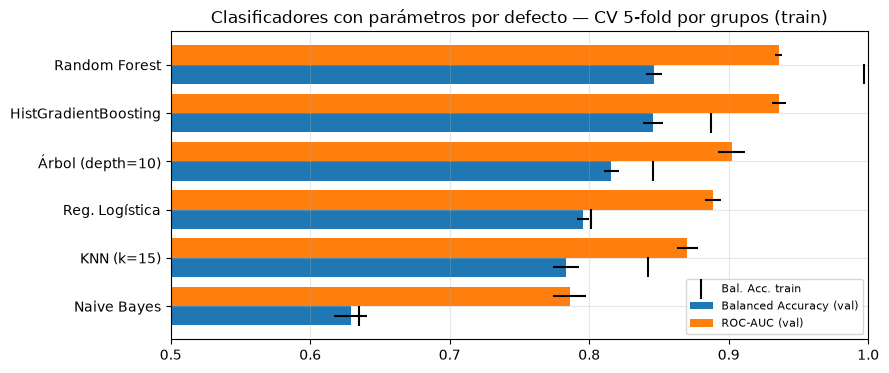

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = tabla.index[::-1]
y = np.arange(len(orden))
ax.barh(y - 0.2, tabla.loc[orden, "val_bal_acc"], 0.4, xerr=tabla.loc[orden, "val_bal_acc_std"], label="Balanced Accuracy (val)")
ax.barh(y + 0.2, tabla.loc[orden, "val_roc_auc"], 0.4, xerr=tabla.loc[orden, "val_roc_auc_std"], label="ROC-AUC (val)")
ax.scatter(tabla.loc[orden, "train_bal_acc"], y - 0.2, marker="|", s=200, c="k", label="Bal. Acc. train", zorder=3)
ax.set_yticks(y, orden); ax.set_xlim(0.5, 1.0); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Clasificadores con parámetros por defecto — CV 5-fold por grupos (train)")
C.guardar(fig, "07_clasificadores.png"); plt.show()

## Breve calibración de hiperparámetros de los dos mejores

`GridSearchCV` con el mismo esquema de CV por grupos, seleccionando por **balanced accuracy** (y mirando ROC-AUC como segunda métrica). Grillas chicas a propósito: el objetivo es un baseline razonable, la optimización fuerte es el paso 4.

In [5]:
def grid(modelo, params):
    g = GridSearchCV(C.pipeline("Original (28)", modelo), params, scoring=C.SCORING, refit="bal_acc",
                     cv=C.crear_cv("grupo"), n_jobs=5, return_train_score=True)
    g.fit(X_train, y_train, groups=grupos)
    r = pd.DataFrame(g.cv_results_)
    cols = [c for c in r if c.startswith("param_")]
    r = r[cols + ["mean_train_bal_acc", "mean_test_bal_acc", "std_test_bal_acc", "mean_test_roc_auc"]]
    return g, r.sort_values("mean_test_bal_acc", ascending=False).round(4)

t = time.time()
g_rf, r_rf = grid(RandomForestClassifier(300, class_weight="balanced", n_jobs=2, random_state=C.RANDOM_STATE),
                  {"randomforestclassifier__min_samples_leaf": [1, 3, 10],
                   "randomforestclassifier__max_features": ["sqrt", 0.5]})
print(f"RF ({time.time()-t:.0f}s)"); display(r_rf)

RF (93s)


,param_randomforestclassifier__max_features,param_randomforestclassifier__min_samples_leaf,mean_train_bal_acc,mean_test_bal_acc,std_test_bal_acc,mean_test_roc_auc
3,0.5,1,0.9968,0.8462,0.0054,0.9345
0,sqrt,1,0.9968,0.8461,0.0057,0.9358
4,0.5,3,0.9726,0.8452,0.0068,0.9347
5,0.5,10,0.9133,0.8438,0.0060,0.9321
1,sqrt,3,0.9551,0.8419,0.0046,0.9347
2,sqrt,10,0.8984,0.8369,0.0062,0.9311


In [6]:
t = time.time()
g_hgb, r_hgb = grid(HistGradientBoostingClassifier(class_weight="balanced", max_iter=500, random_state=C.RANDOM_STATE),
                    {"histgradientboostingclassifier__learning_rate": [0.05, 0.1],
                     "histgradientboostingclassifier__max_leaf_nodes": [31, 63, 127]})
print(f"HGB ({time.time()-t:.0f}s)"); display(r_hgb)

HGB (41s)


,param_histgradientboostingclassifier__learning_rate,param_histgradientboostingclassifier__max_leaf_nodes,mean_train_bal_acc,mean_test_bal_acc,std_test_bal_acc,mean_test_roc_auc
2,0.05,127,0.9538,0.8524,0.0058,0.9390
3,0.10,31,0.9161,0.8480,0.0058,0.9374
1,0.05,63,0.9339,0.8474,0.0067,0.9381
5,0.10,127,0.9521,0.8468,0.0049,0.9381
0,0.05,31,0.9131,0.8463,0.0067,0.9368
4,0.10,63,0.9455,0.8458,0.0049,0.9367


In [7]:
cand = {
    "RF ajustado": (g_rf.best_estimator_, g_rf.best_params_),
    "HGB ajustado": (g_hgb.best_estimator_, g_hgb.best_params_),
}
res_aj = {k: C.evaluar_cv(m, X_train, y_train, grupos) for k, (m, _) in cand.items()}
for k, (_, p) in cand.items():
    print(k, {kk.split("__")[1]: v for kk, v in p.items()})
tabla_aj = pd.concat([tabla.loc[["Random Forest", "HistGradientBoosting"]], pd.DataFrame(res_aj).T])
tabla_aj[["train_bal_acc", "val_bal_acc", "val_bal_acc_std", "val_roc_auc", "brecha_bal_acc", "seg"]].round(4)

RF ajustado {'max_features': 0.5, 'min_samples_leaf': 1}
HGB ajustado {'learning_rate': 0.05, 'max_leaf_nodes': 127}


,train_bal_acc,val_bal_acc,val_bal_acc_std,val_roc_auc,brecha_bal_acc,seg
Random Forest,0.9968,0.8461,0.0057,0.9358,0.1506,13.5044
HistGradientBoosting,0.8874,0.8458,0.0070,0.9360,0.0415,1.6456
RF ajustado,0.9968,0.8462,0.0054,0.9345,0.1505,13.5078
HGB ajustado,0.9538,0.8524,0.0058,0.9390,0.1015,6.6671


## Elección del baseline

In [8]:
mejor = max(res_aj, key=lambda k: res_aj[k]["val_bal_acc"])
baseline = cand[mejor][0]
print("Baseline elegido:", mejor)
print(f"  val Balanced Accuracy = {res_aj[mejor]['val_bal_acc']:.4f} ± {res_aj[mejor]['val_bal_acc_std']:.4f}")
print(f"  val ROC-AUC           = {res_aj[mejor]['val_roc_auc']:.4f}")
print(f"  brecha train-val (BA) = {res_aj[mejor]['brecha_bal_acc']:.4f}")
joblib.dump({"nombre": mejor, "modelo": baseline, "set": "Original (28)", "tabla": tabla, "tabla_aj": tabla_aj,
             "comp_esquemas": comp}, C.RESULTADOS / "paso2_baseline.joblib")

Baseline elegido: HGB ajustado
  val Balanced Accuracy = 0.8524 ± 0.0058
  val ROC-AUC           = 0.9390
  brecha train-val (BA) = 0.1015


['resultados\\paso2_baseline.joblib']

## Conclusiones del paso 2

- **Validación:** la CV aleatoria infla la balanced accuracy de validación en ~3.4 puntos (0.881 vs 0.846) porque el modelo reconoce reservas duplicadas. Por eso comparamos siempre con **StratifiedGroupKFold** (5 folds, sólo train).
- **Familias:** los ensembles de árboles dominan claramente (BA ≈ 0.85, AUC ≈ 0.94). La regresión logística queda en 0.80 y KNN en 0.78: las relaciones son **no lineales** y hay muchas categóricas (regiones, ids) donde las distancias funcionan mal. Naive Bayes (0.63) sufre porque sus supuestos de independencia y normalidad no se cumplen.
- **Hiperparámetros:**
  - En **Random Forest** la grilla casi no cambia nada (0.846). El bosque ya está en su techo: sobreajusta train (0.997) y lo compensa promediando.
  - En **HistGradientBoosting**, más hojas (127) con `learning_rate` 0.05 sube la validación a **0.852** (+0.7 puntos).
- **Baseline elegido: HistGradientBoosting ajustado** (`learning_rate=0.05`, `max_leaf_nodes=127`, `max_iter=500`, `class_weight="balanced"`), sobre las 28 variables originales:
  - **Balanced Accuracy = 0.852 ± 0.006**, **ROC-AUC = 0.939**.
  - Es el mejor en las dos métricas, es rápido (~7 s por fit), lo que permite iterar en el enfoque *data-centered*, y tiene una brecha train–val (0.10) menor que la de RF (0.15).
- En el siguiente notebook dejamos este modelo **fijo** y analizamos **dónde se equivoca**.